In [ ]:
import torch
import random

import numpy as np
import matplotlib.pyplot as plt

from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA

from sklearn.decomposition import PCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# For deterministic CUDA operations
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Data

In [3]:
## Data from https://arxiv.org/abs/2306.13503

m1, m2, m3, = [0., 0.], [0., 0.], [0., 0.]
means = torch.tensor([m1, m2, m3])

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma0 = torch.tensor([[2.9, 1.6], [1.6, 1.0]])
Sigma1 = torch.tensor([[2.9, -1.6], [-1.6, 1.0]])
Sigma2 = torch.tensor([[0.03, 0.], [0., 4.0]]) # torch.tensor([[0.2, 0.], [0., 3.0]])
Sigmas = torch.stack([Sigma0, Sigma1, Sigma2])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * 1000 for k in range(3)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

concat_samples = concat_samples - torch.mean(concat_samples, axis=0, keepdims=True)

(-5.0, 5.0)

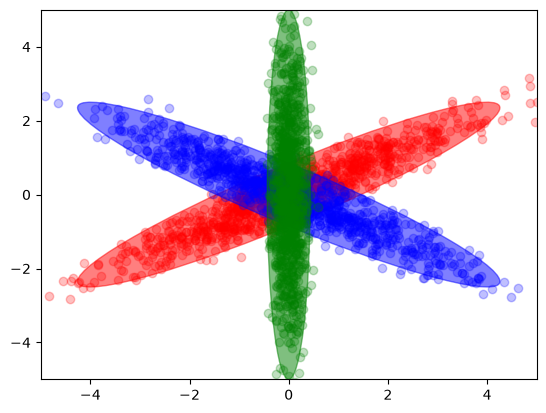

In [4]:
colors = ["red", "blue", "green"]

for k in range(len(samples)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.25, c=colors[k])
    draw_cov(means[k], Sigmas[k], nstd=2.5, color=colors[k])

plt.xlim(-5, 5)
plt.ylim(-5, 5)

In [5]:
samples_v2 = torch.zeros((len(means) * 10, n//10, d))

for k in range(len(means)):
    for i in range(10):
        samples_v2[k*10+i] = samples[k][i*100:(i+1)*100]

samples = samples_v2
y_samples = torch.from_numpy(np.concatenate([[k] * 100 for k in range(30)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

### PCA

In [6]:
def plot_pca(pca, data):
    eigenvectors = pca.components_
    explained_var = 0.5 + pca.explained_variance_ratio_    

    for k in range(len(data)):
        plt.scatter(data[k][:,0], data[k][:,1], c=colors[k//10], alpha=0.25)

    # Plot first PC
    plt.quiver(
        0, 0,
        explained_var[0]*eigenvectors[0][0], explained_var[0]*eigenvectors[0][1],
        color="black", scale=3, label="PCA on one sample per distribution"
    )

    plt.quiver(
        0, 0,
        -explained_var[0]*eigenvectors[0][0], -explained_var[0]*eigenvectors[0][1],
        color="black", scale=3, label="PCA on one sample per distribution"
    )

    # Plot second PC
    plt.quiver(
        0, 0,
        explained_var[1]*eigenvectors[1][0], explained_var[1]*eigenvectors[1][1],
        color="black", scale=3, label="PCA on one sample per distribution"
    )

    plt.quiver(
        0, 0,
        -explained_var[1]*eigenvectors[1][0], -explained_var[1]*eigenvectors[1][1],
        color="black", scale=3, label="PCA on one sample per distribution"
    )

    plt.plot([0, 0], [-5, 5], "--", c="k")
    plt.plot([-5, 5], [0, 0], "--", c="k")

    plt.xlim(- 5, 5)
    plt.ylim(-5, 5)

    plt.axis("off")

    plt.show()

In [7]:
# PCA on one point per distribution

X = torch.stack([samples[k][0] for k in range(len(samples))])
X = X - torch.mean(X, axis=0, keepdims=True)

pca_one_samples = PCA()
pca_one_samples.fit(X.numpy())

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

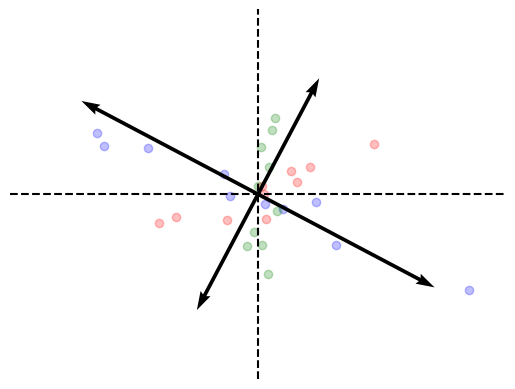

In [8]:
plot_pca(pca_one_samples, X[:,None])

In [9]:
# PCA on all the points

pca = PCA()
pca.fit(concat_samples.numpy())

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

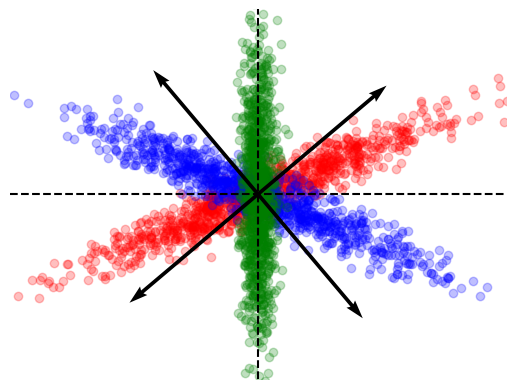

In [10]:
plot_pca(pca, samples)

### UAPCA

In [ ]:
pca_distributional = UAPCA(2)
pca_distributional.fit_from_samples(concat_samples, y_samples)

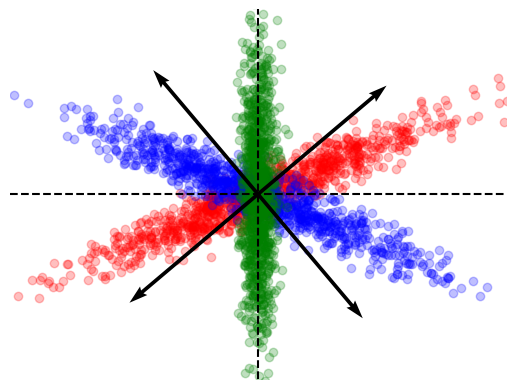

In [12]:
plot_pca(pca_distributional, samples)

### Lifted PCA

In [13]:
lifted_pca = LiftedPCA(n_components=1, n_samples=3)
lifted_pca.fit(samples, solver="fixed_weights")
eigenvectors_lifted = lifted_pca.components_

INFO:2026-08-25 17:06:06,176:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


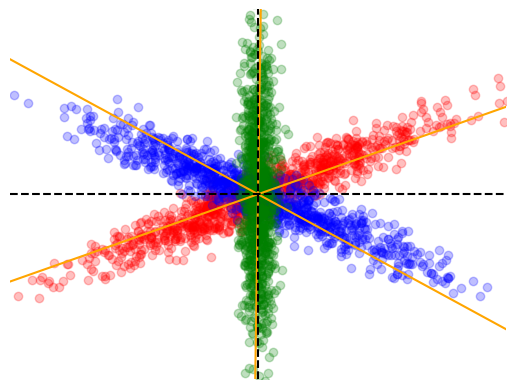

In [14]:
for k in range(len(samples)):
    plt.scatter(samples[k][:,0], samples[k][:,1], c=colors[k//10], alpha=0.25)

ts = torch.linspace(-10, 10, 100)

if lifted_pca.weights_ is None:
    weights = np.ones(len(eigenvectors_lifted))
else:
    weights = lifted_pca.weights_.detach().numpy()

min_weights = weights.min()
max_weights = weights.max()
diff = max_weights - min_weights

if diff == 0:
    alpha = weights
else:
    alpha = 0.05 + 0.95 * (weights - min_weights) / diff


for k in range(len(eigenvectors_lifted)):
    pc = ts[:,None] * eigenvectors_lifted[k,:,0][None]
    plt.plot(pc[:,0], pc[:,1], c="orange", alpha=alpha[k])

plt.plot([0, 0], [-5, 5], "--", c="k")
plt.plot([-5, 5], [0, 0], "--", c="k")

plt.xlim(- 5, 5)
plt.ylim(-5, 5)

plt.axis("off")

plt.show()

In [15]:
lifted_pca.cost_barycenter(samples)

np.float64(0.46215274183313454)

In [16]:
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support")
eigenvectors_lifted = lifted_pca.components_

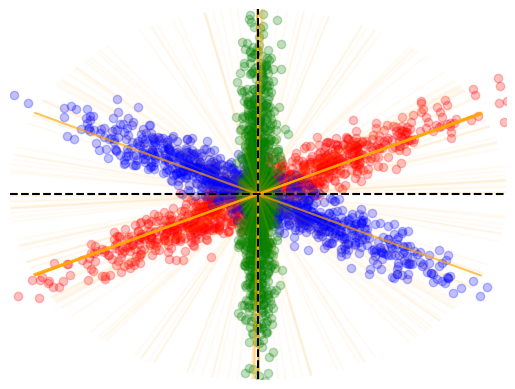

In [17]:
for k in range(len(samples)):
    plt.scatter(samples[k][:,0], samples[k][:,1], c=colors[k//10], alpha=0.25)

ts = torch.linspace(-5, 5, 100)

if lifted_pca.weights_ is None:
    weights = np.ones(len(eigenvectors_lifted))
else:
    weights = lifted_pca.weights_.detach().numpy()

min_weights = weights.min()
max_weights = weights.max()
diff = max_weights - min_weights

if diff == 0:
    alpha = weights
else:
    alpha = 0.05 + 0.95 * (weights - min_weights) / diff


for k in range(len(eigenvectors_lifted)):
    pc = ts[:,None] * eigenvectors_lifted[k,:,0][None]
    plt.plot(pc[:,0], pc[:,1], c="orange", alpha=alpha[k])

plt.plot([0, 0], [-5, 5], "--", c="k")
plt.plot([-5, 5], [0, 0], "--", c="k")

plt.xlim(- 5, 5)
plt.ylim(-5, 5)

plt.axis("off")

plt.show()

In [18]:
lifted_pca.cost_barycenter(samples)

np.float64(0.5274630348548353)

In [38]:
means = torch.zeros((len(samples), samples[0].shape[1]))
for k in range(len(samples)):
    means[k] = torch.mean(samples[k], axis=0, keepdims=True)

full_mean = torch.mean(means, axis=0)

Gammas = torch.zeros(len(samples), d, d)
for k in range(len(samples)):
    Cs = samples[k] - means[k][None]
    covs_X = torch.einsum(
        "nd, nk -> dk", Cs, Cs
    ) / len(samples[k])
    Gammas[k] = (means[k] - full_mean)[:,None] @ (means[k] - full_mean)[None,:] + covs_X

In [44]:
## Lower bound of Prop 2.2
torch.einsum("...ii", torch.mean(Gammas, axis=0))-torch.einsum("...ii", torch.mean(Gammas, axis=0))

tensor(0.)

In [48]:
## Upper bound of Prop 2.4
eigenvalues, eigenvectors = torch.linalg.eigh(torch.mean(Gammas, axis=0))
eigenvals_sorted, inds_sort = torch.sort(eigenvalues, descending=True) 
print(torch.sum(eigenvals_sorted[1:]))


tensor(1.8425)
